<a href="https://colab.research.google.com/github/Ghanshyammali10/ML_Parcticals/blob/main/ML_PR_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*   Student Name: Ghanshyam Ramchandra Mali
*   Div: CSE-A
*   Practical Batch: A-1
*   Roll No: 05
*   Date: 21/10/2026
*   Practical No: 7
*   Practical Name: Implement K-Means clustering. Find the optimal number of clusters using the Elbow method and Silhouette score.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.figsize'] = (6,5)
plt.rcParams['figure.dpi'] = 150
sns.set_style('darkgrid')

In [ ]:
df = pd.read_csv('Mall_Customers.csv')
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [ ]:
df.drop(['CustomerID', 'Gender', 'Age'], axis=1, inplace=True)
df.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


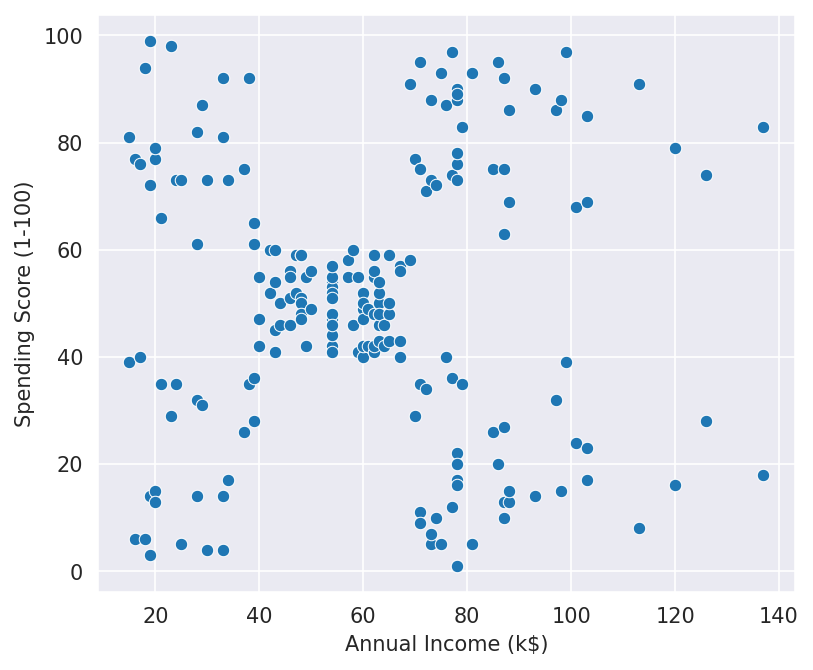

In [ ]:
sns.scatterplot(x=df['Annual Income (k$)'], y=df['Spending Score (1-100)'])
plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
x = sc.fit_transform(df)
x[:10]

array([[-1.73899919, -0.43480148],
       [-1.73899919,  1.19570407],
       [-1.70082976, -1.71591298],
       [-1.70082976,  1.04041783],
       [-1.66266033, -0.39597992],
       [-1.66266033,  1.00159627],
       [-1.62449091, -1.71591298],
       [-1.62449091,  1.70038436],
       [-1.58632148, -1.83237767],
       [-1.58632148,  0.84631002]])

In [ ]:
from sklearn.cluster import KMeans
km = KMeans()
yp = km.fit_predict(x)
yp

array([4, 3, 4, 7, 4, 7, 4, 3, 4, 7, 4, 3, 4, 7, 4, 7, 4, 7, 4, 3, 4, 7,
       4, 7, 4, 3, 4, 7, 4, 3, 4, 7, 4, 3, 4, 3, 4, 7, 4, 7, 4, 3, 4, 7,
       4, 7, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 1, 2, 1, 2, 1, 6, 1, 6, 1,
       2, 1, 6, 1, 6, 1, 6, 1, 6, 1, 2, 1, 6, 1, 2, 1, 6, 1, 6, 1, 6, 1,
       6, 1, 6, 1, 6, 1, 2, 1, 6, 1, 2, 1, 6, 1, 2, 1, 6, 1, 6, 1, 6, 1,
       6, 1, 6, 1, 2, 1, 5, 1, 2, 1, 5, 1, 5, 1, 5, 1, 5, 1, 5, 1, 5, 1,
       5, 1], dtype=int32)

In [ ]:
len(yp)

200

In [ ]:
# cluster centres (standardised scale)
km.cluster_centers_

array([[-0.22527999, -0.0072535 ],
       [ 0.99158305,  1.23950275],
       [ 0.7420137 , -0.63243852],
       [-1.31065338,  1.52784409],
       [-1.30751869, -1.13696536],
       [ 1.98729133, -1.22579078],
       [ 0.72674593, -1.51015871],
       [-1.30550353,  0.82689924]])

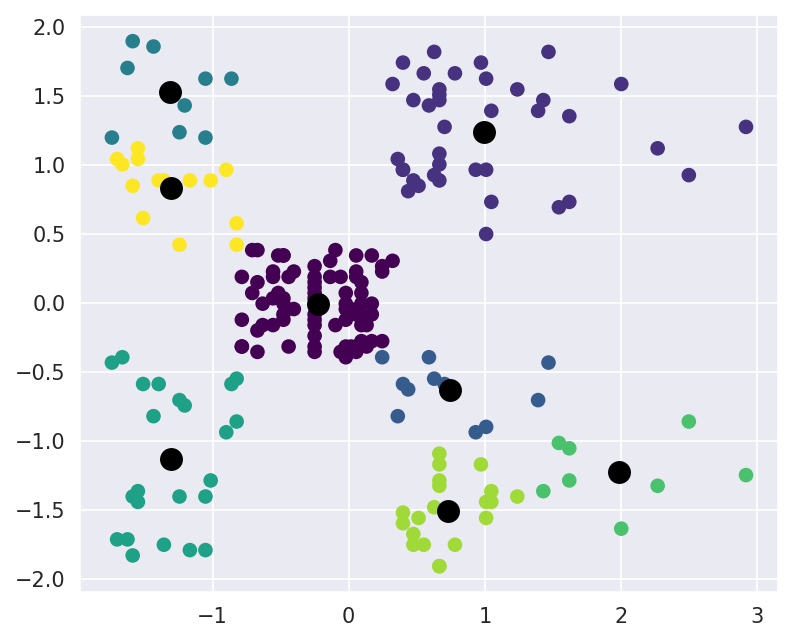

In [ ]:
plt.scatter(x[:,0], x[:,1], c=yp, cmap='viridis')
plt.scatter(km.cluster_centers_[:,0], km.cluster_centers_[:,1], c='black', s=100)
plt.show()

In [ ]:
# inertia = sum of squared distances of each sample to its nearest centre
km.inertia_

48.67297628593761

In [ ]:
wcss = []

for i in range(1,20):
    km = KMeans(n_clusters=i)
    km.fit_predict(x)
    wcss.append(km.inertia_)

wcss

[399.99999999999994,
 270.02616084451483,
 157.70400815035939,
 108.92131661364358,
 98.80769272556533,
 55.37581558455639,
 46.85522014153859,
 42.004276238393075,
 33.97733820619394,
 29.845554552381152,
 27.438908580936825,
 24.9381569557508,
 26.254337661821037,
 20.55722100098265,
 20.409097029219396,
 16.302534034187158,
 15.011894209645392,
 14.17423308784896,
 13.768583113071136]

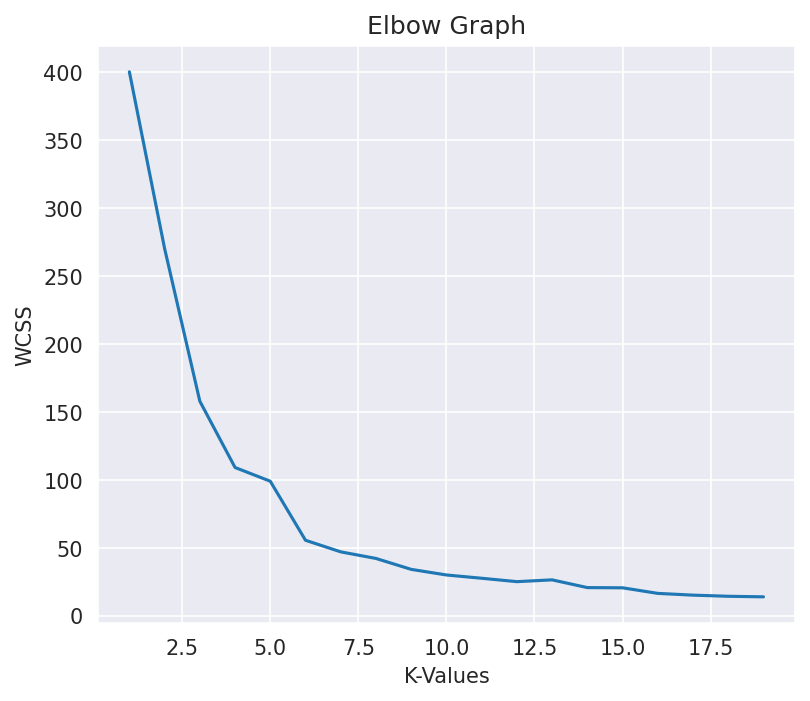

In [ ]:
plt.plot(range(1,20),wcss)
plt.xlabel('K-Values')
plt.ylabel('WCSS')
plt.title('Elbow Graph')
plt.show()

In [ ]:
from sklearn.metrics import silhouette_score
silhouette_score(x,yp)

np.float64(0.4687938894852994)

K = 2, Silhouette Score = 0.321
K = 3, Silhouette Score = 0.467
K = 4, Silhouette Score = 0.494
K = 5, Silhouette Score = 0.555
K = 6, Silhouette Score = 0.540
K = 7, Silhouette Score = 0.528
K = 8, Silhouette Score = 0.455
K = 9, Silhouette Score = 0.457
K = 10, Silhouette Score = 0.443


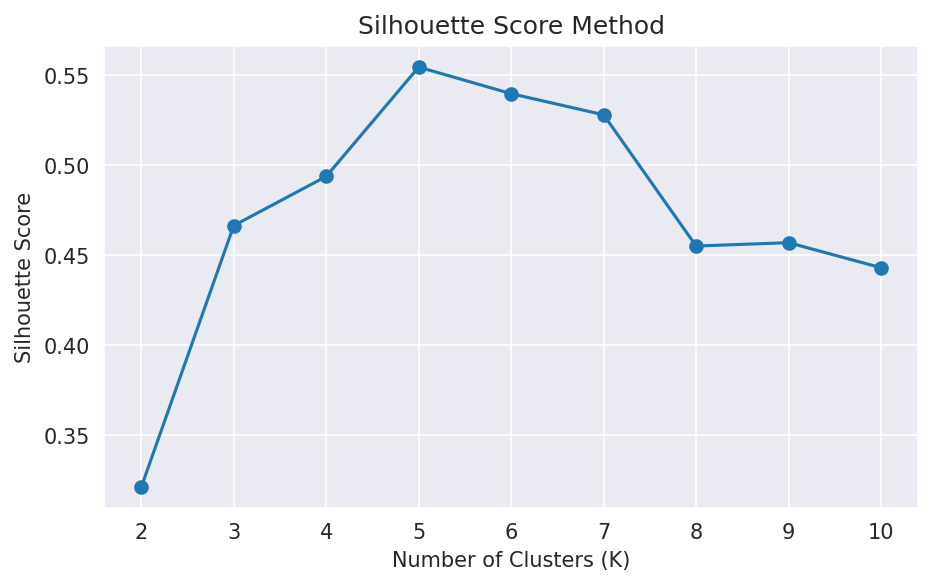

In [ ]:
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = kmeans.fit_predict(x)
    score = silhouette_score(x, labels)
    silhouette_scores.append(score)
    print(f"K = {k}, Silhouette Score = {score:.3f}")

plt.figure(figsize=(7, 4))
plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.title('Silhouette Score Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()